# PharmaSafeIQ - FDA Adverse Events (2015-2025)
Python cleaning -> SQLite -> 5 SQL business questions.

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Load & Data Quality Check

In [2]:
df= pd.read_csv("fda_adverse_events_2015_2026_CLEAN.csv")

In [3]:
df

,report_id,receive_date,year,month,quarter,serious,serious_flags,is_fatal,is_hospitalized,is_life_threat,...,manufacturer,pharm_class,num_drugs,drug_count_category,patient_age_years,age_group,patient_sex,patient_weight_kg,country,report_age_days
0,10004718,2015-02-11,2015,2,2015Q1,Yes,Hospitalization,False,True,False,...,Glaxosmithkline Llc,Unknown,7,Polypharmacy(6+),64.0,Middle-Aged(41-65),Female,NaN,US,4063
1,10004926,2015-02-13,2015,2,2015Q1,Yes,Hospitalization,False,True,False,...,Bayer Healthcare Pharmaceuticals Inc.,Progestin [EPC]; Progestin-containing Intraute...,1,Single,20.0,Adult(19-40),Female,54.00,US,4061
2,10005223,2015-02-19,2015,2,2015Q1,Yes,Hospitalization,False,True,False,...,Cordavis Limited; Abbvie Inc.,Unknown,14,Polypharmacy(6+),60.0,Middle-Aged(41-65),Female,NaN,US,4055
3,10005378,2015-02-17,2015,2,2015Q1,Yes,Hospitalization,False,True,False,...,Unknown,Unknown,34,Polypharmacy(6+),20.0,Adult(19-40),Female,NaN,BR,4057
4,10005980,2015-02-21,2015,2,2015Q1,Yes,NaN,False,False,False,...,Live Betr Llc; American Sales Company; Little ...,Unknown,7,Polypharmacy(6+),NaN,Unknown,Female,NaN,GB,4053
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
527995,22807486,2025-12-29,2025,12,2025Q4,Yes,NaN,False,False,False,...,"Ucb, Inc.",Tumor Necrosis Factor Blocker [EPC],1,Single,38.0,Adult(19-40),Unknown,NaN,Unknown,89
527996,22808018,2025-12-08,2025,12,2025Q4,No,NaN,False,False,False,...,Sanofi-Aventis U.S. Llc,Interleukin-4 Receptor alpha Antagonist [EPC],1,Single,68.0,Senior(66-80),Female,65.76,US,110
527997,22810302,2025-12-31,2025,12,2025Q4,No,NaN,False,False,False,...,Unknown,Unknown,1,Single,79.0,Senior(66-80),Female,NaN,US,87
527998,22810346,2025-12-24,2025,12,2025Q4,No,NaN,False,False,False,...,Pharmacia & Upjohn Company Llc,Unknown,2,2-3 Drugs,79.0,Senior(66-80),Female,NaN,US,94


In [4]:
df.dtypes

report_id                int64
receive_date               str
year                     int64
month                    int64
quarter                    str
serious                    str
serious_flags              str
is_fatal                  bool
is_hospitalized           bool
is_life_threat            bool
is_disabling              bool
reactions                  str
primary_reaction           str
reaction_outcomes          str
patient_recovered         bool
num_reactions            int64
suspect_drug               str
brand_name                 str
drug_route                 str
drug_indication            str
manufacturer               str
pharm_class                str
num_drugs                int64
drug_count_category        str
patient_age_years      float64
age_group                  str
patient_sex                str
patient_weight_kg      float64
country                    str
report_age_days          int64
dtype: object

In [5]:
df['receive_date'] = pd.to_datetime(df['receive_date'])

In [6]:
df.isnull().sum()/len(df)*100

report_id               0.000000
receive_date            0.000000
year                    0.000000
month                   0.000000
quarter                 0.000000
serious                 0.000000
serious_flags          57.027652
is_fatal                0.000000
is_hospitalized         0.000000
is_life_threat          0.000000
is_disabling            0.000000
reactions               0.000000
primary_reaction        0.000000
reaction_outcomes       0.000000
patient_recovered       0.000000
num_reactions           0.000000
suspect_drug            0.000000
brand_name              0.000000
drug_route              0.000000
drug_indication         0.000000
manufacturer            0.000000
pharm_class             0.000000
num_drugs               0.000000
drug_count_category     0.000000
patient_age_years      28.694886
age_group               0.000000
patient_sex             0.000000
patient_weight_kg      71.955114
country                 0.000000
report_age_days         0.000000
dtype: flo

In [7]:
missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    'Missing_Percentage', ascending=False
)

missing_summary

,Missing_Count,Missing_Percentage
patient_weight_kg,379923,71.96
serious_flags,301106,57.03
patient_age_years,151509,28.69
month,0,0.00
year,0,0.00
report_id,0,0.00
serious,0,0.00
is_fatal,0,0.00
is_hospitalized,0,0.00
is_life_threat,0,0.00


**Insight:** Dataset mein 528,000 reports hain. Missing values: `patient_weight_kg` 71.96% (379,923), `serious_flags` 57.03% (301,106) aur `patient_age_years` 28.69% (151,509). Baaki saare columns 0% missing hain.

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df['report_id'].duplicated().sum()

np.int64(0)

**Insight:** Full-row duplicates = 0 aur `report_id` duplicates = 0, matlab har row ek unique report hai. Duplicate removal ki zaroorat nahi.

In [10]:
df['patient_sex'].value_counts()

patient_sex
Female     279155
Male       198932
Unknown     49913
Name: count, dtype: int64

In [11]:
df['serious'].value_counts()

serious
Yes    395000
No     133000
Name: count, dtype: int64

**Insight:** Female 279,155 (52.9%), Male 198,932 (37.7%), Unknown 49,913 (9.5%). Serious = Yes 395,000 (74.8%) vs No 133,000 (25.2%). Ye exact round numbers batate hain ki data ek sample hai, poora FAERS nahi.

## 2. Cleaning Decisions

In [12]:
df['serious_flags'] = df['serious_flags'].fillna('Unknown')

`serious_flags` null tab hota hai jab report ka koi specific flag nahi tha, isliye missing ko `'Unknown'` label kiya (rows drop karne se 57% data jaata).

In [13]:
df = df.drop(columns='patient_weight_kg')

`patient_weight_kg` mein 71.96% missing tha. Imputation se bias aata, aur kisi business question mein weight use nahi hota, isliye column drop kiya.

In [14]:
df.isnull().sum()

report_id                   0
receive_date                0
year                        0
month                       0
quarter                     0
serious                     0
serious_flags               0
is_fatal                    0
is_hospitalized             0
is_life_threat              0
is_disabling                0
reactions                   0
primary_reaction            0
reaction_outcomes           0
patient_recovered           0
num_reactions               0
suspect_drug                0
brand_name                  0
drug_route                  0
drug_indication             0
manufacturer                0
pharm_class                 0
num_drugs                   0
drug_count_category         0
patient_age_years      151509
age_group                   0
patient_sex                 0
country                     0
report_age_days             0
dtype: int64

In [15]:
df[['patient_age_years', 'num_reactions', 'num_drugs', 'report_age_days']].describe()

,patient_age_years,num_reactions,num_drugs,report_age_days
count,376491.000000,528000.000000,528000.000000,528000.000000
mean,55.942629,6.280659,8.698930,2096.257782
std,19.567057,8.447020,19.416267,1160.025989
min,0.000000,1.000000,1.000000,87.000000
25%,45.000000,2.000000,2.000000,1092.750000
50%,59.000000,4.000000,4.000000,2096.500000
75%,70.000000,7.000000,10.000000,3100.250000
max,120.000000,253.000000,2108.000000,4104.000000


**Insight:** Average age 55.94 saal, median 59. `num_drugs` ka median 4 par mean 8.70 hai aur max 2108, matlab right-skewed outliers hain. `num_reactions` ka max 253 hai. Outliers ko delete nahi kiya (ye real reports ho sakti hain), bas buckets (1-4, 5-9, 10+) use kiye taaki extreme values result na bigaden.

In [16]:
# Age ke suspicious values check
print('Age > 100:', (df['patient_age_years'] > 100).sum())
print('Age == 0:', (df['patient_age_years'] == 0).sum())
print('Age null:', df['patient_age_years'].isnull().sum())

Age > 100: 28
Age == 0: 828
Age null: 151509


Age null rows (151,509) ko `patient_age_years` wale analysis (Q3) mein se exclude kiya gaya hai. Baaki analyses mein ye rows use hoti hain.

In [17]:
df[df['num_drugs'] > 100][['report_id', 'suspect_drug', 'num_drugs']]

,report_id,suspect_drug,num_drugs
14338,10571407,ELPLAT,103
15134,10649930,AZACITIDINE,146
26628,10568491,MEPERIDINE HYDROCHLORIDE,208
47462,11366151,LENALIDOMIDE,108
48722,10538369,PALIVIZUMAB,109
...,...,...,...
527793,22625206,NAPROXEN SODIUM; NAPROXEN SODIUM 220MG; NAPROX...,197
527820,22651632,VALPROIC ACID,112
527822,22653390,CITALOPRAM; CITALOPRAM HYDROBROMIDE,120
527897,22714614,LATANOPROST,101


In [18]:
df.loc[df['num_drugs'] == 2108,
       ['report_id', 'suspect_drug', 'num_drugs']]

,report_id,suspect_drug,num_drugs
441442,18248303,OMEPRAZOLE; OMEPRAZOLE MAGNESIUM,2108


In [19]:
# report_id se verify (pehle index 441442 use hua tha, jo report_id nahi hai)
df.loc[df['report_id'] == 18248303, ['report_id', 'suspect_drug', 'num_drugs', 'num_reactions']]

,report_id,suspect_drug,num_drugs,num_reactions
441442,18248303,OMEPRAZOLE; OMEPRAZOLE MAGNESIUM,2108,23


In [20]:
df['num_drugs'].value_counts().head(10)

num_drugs
1     106633
2      74013
3      52053
4      41224
5      30748
6      26320
7      21318
8      18960
9      16359
10     14318
Name: count, dtype: int64

In [21]:
df.loc[df['num_drugs'].idxmax(), ['report_id', 'suspect_drug', 'num_drugs']]

report_id                               18248303
suspect_drug    OMEPRAZOLE; OMEPRAZOLE MAGNESIUM
num_drugs                                   2108
Name: 441442, dtype: object

In [22]:
df['actual_drug_count'] = df['suspect_drug'].str.count(';') + 1

(df['num_drugs'] != df['actual_drug_count']).sum()

np.int64(422426)

**Note:** `num_drugs` poori report ke saare drugs gina hai, jabki `actual_drug_count` sirf `suspect_drug` column ke drugs (`;` se split). Isliye 422,426 rows mein difference aana error nahi hai, dono alag cheezein naap rahe hain. Analysis mein `num_drugs` hi use kiya hai.

In [23]:
df[['suspect_drug', 'num_drugs', 'actual_drug_count']].head(15)

,suspect_drug,num_drugs,actual_drug_count
0,FLUTICASONE PROPIONATE AND SALMETEROL XINAFOATE,7,1
1,LEVONORGESTREL,1,1
2,ADALIMUMAB,14,1
3,MABTHERA,34,1
4,CETIRIZINE HYDROCHLORIDE; CETIRIZINE; CETIRIZI...,7,4
5,RIVAROXABAN,3,1
6,ATORVASTATIN CALCIUM,4,1
7,ATORVASTATIN CALCIUM,8,1
8,ATORVASTATIN CALCIUM,8,1
9,ATORVASTATIN CALCIUM,8,1


## 3. SQLite Setup

In [24]:
import sqlite3

con = sqlite3.connect('PharmaSafeIQ.db')

In [25]:
def sql(query):
    return pd.read_sql_query(query, con)

In [26]:
pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table'",
    con
)

,name
0,adverse_events


In [27]:
df.to_sql(
    'adverse_events',
    con,
    if_exists='replace',
    index=False,
    chunksize=50000
)

528000

In [28]:
pd.read_sql_query(
    "SELECT COUNT(*) AS total_rows FROM adverse_events",
    con
)

,total_rows
0,528000


**Insight:** `adverse_events` table mein 528,000 rows load hue, jo DataFrame se match karte hain.

## Q1. Kaunsi drugs ka fatality rate sabse zyada hai? (min 500 reports)

**Limitation:** `suspect_drug` mein kuch jagah `;` se joined combinations hain, aur fatal rate reports ke andar ka share hai (FAERS mein denominator, yaani kitne log drug lete hain, nahi hota). Isse drug ka asli risk nahi, reporting-based signal samjho.

In [29]:
Q1 = """
SELECT
    suspect_drug AS drug,
    COUNT(*) AS reports,
    SUM(is_fatal) AS fatal_reports,
    ROUND(100.0 * SUM(is_fatal) / COUNT(*), 2) AS fatal_rate_pct,
    ROUND(100.0 * SUM(is_hospitalized) / COUNT(*), 2) AS hospitalized_rate_pct,
    RANK() OVER (
        ORDER BY 1.0 * SUM(is_fatal) / COUNT(*) DESC
    ) AS risk_rank
FROM adverse_events
GROUP BY suspect_drug
HAVING COUNT(*) >= 500
ORDER BY fatal_rate_pct DESC
LIMIT 10;
"""

q1 = sql(Q1)
q1

,drug,reports,fatal_reports,fatal_rate_pct,hospitalized_rate_pct,risk_rank
0,PIMAVANSERIN TARTRATE,3364,1605,47.71,31.60,1
1,SITAGLIPTIN,554,260,46.93,61.91,2
2,DIANEAL LOW CALCIUM PERITONEAL DIALYSIS SOLUTI...,644,282,43.79,54.35,3
3,DARBEPOETIN ALFA,934,367,39.29,83.40,4
4,RIVAROXABAN,12968,5033,38.81,91.58,5
5,NIVOLUMAB,4572,1749,38.25,60.63,6
6,VENETOCLAX,1008,383,38.00,63.49,7
7,JAKAVI,842,315,37.41,62.00,8
8,GLIVEC,536,189,35.26,36.19,9
9,PEMBROLIZUMAB,1907,649,34.03,55.27,10


C:\Users\HP\AppData\Local\Temp\ipykernel_8268\1801192070.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels([d[:35] for d in q1['drug']])


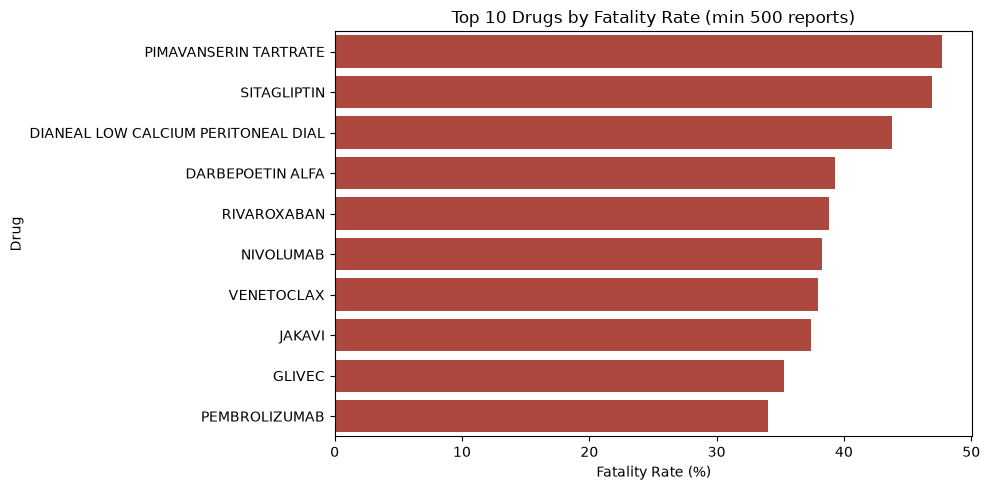

In [30]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=q1, y='drug', x='fatal_rate_pct', color='#c0392b', ax=ax)
ax.set_title('Top 10 Drugs by Fatality Rate (min 500 reports)')
ax.set_xlabel('Fatality Rate (%)')
ax.set_ylabel('Drug')
ax.set_yticklabels([d[:35] for d in q1['drug']])
plt.tight_layout()
plt.show()

**Insight:** Top 10 drugs ka fatality rate 34.03% se 47.71% tak hai, jabki poore dataset ka average 10.28% hai. Pimavanserin Tartrate sabse upar hai (1,605 fatal / 3,364 reports = 47.71%), phir Sitagliptin 46.93% (260 / 554). Rivaroxaban sabse zyada reports wali drug hai top 10 mein (12,968), fatal rate 38.81% aur hospitalization rate 91.58%. Pimavanserin ka hospitalization rate sirf 31.60% hai, matlab uski reports seedhe fatal outcome ki taraf zyada jaati hain.

## Q2. Kaunse manufacturers industry average se zyada risky hain? (min 500 reports)

In [31]:
Q2 = """
WITH industry AS (
    SELECT
        100.0 * SUM(is_fatal) / COUNT(*) AS industry_fatal_rate
    FROM adverse_events
),
manufacturer_risk AS (
    SELECT
        manufacturer,
        COUNT(*) AS total_reports,
        SUM(is_fatal) AS fatal_reports,
        ROUND(100.0 * SUM(is_fatal) / COUNT(*), 2) AS fatal_rate_pct
    FROM adverse_events
    WHERE manufacturer IS NOT NULL
      AND TRIM(manufacturer) != ''
    GROUP BY manufacturer
    HAVING COUNT(*) >= 500
)
SELECT
    m.manufacturer,
    m.total_reports,
    m.fatal_reports,
    m.fatal_rate_pct,
    ROUND(i.industry_fatal_rate, 2) AS industry_average_pct
FROM manufacturer_risk m
CROSS JOIN industry i
WHERE m.fatal_rate_pct > i.industry_fatal_rate
ORDER BY m.fatal_rate_pct DESC
LIMIT 10;
"""

q2 = sql(Q2)
q2

,manufacturer,total_reports,fatal_reports,fatal_rate_pct,industry_average_pct
0,Acadia Pharmaceuticals Inc.,3367,1605,47.67,10.28
1,"Regeneron Pharmaceuticals, Inc.",521,168,32.25,10.28
2,Merck Sharp & Dohme Llc,3544,1129,31.86,10.28
3,Aurobindo Pharma Limited; Teva Pharmaceuticals...,741,211,28.48,10.28
4,Purdue Pharma Lp,1461,408,27.93,10.28
5,Unifirst First Aid Corporation; Topco Associat...,1099,301,27.39,10.28
6,Eisai Inc.,874,233,26.66,10.28
7,"Actelion Pharmaceuticals Us, Inc.",4398,1164,26.47,10.28
8,"Slate Run Pharmaceuticals, Llc; Xgen Pharmaceu...",569,146,25.66,10.28
9,Pfizer Laboratories Div Pfizer Inc; Viatris Sp...,879,218,24.80,10.28


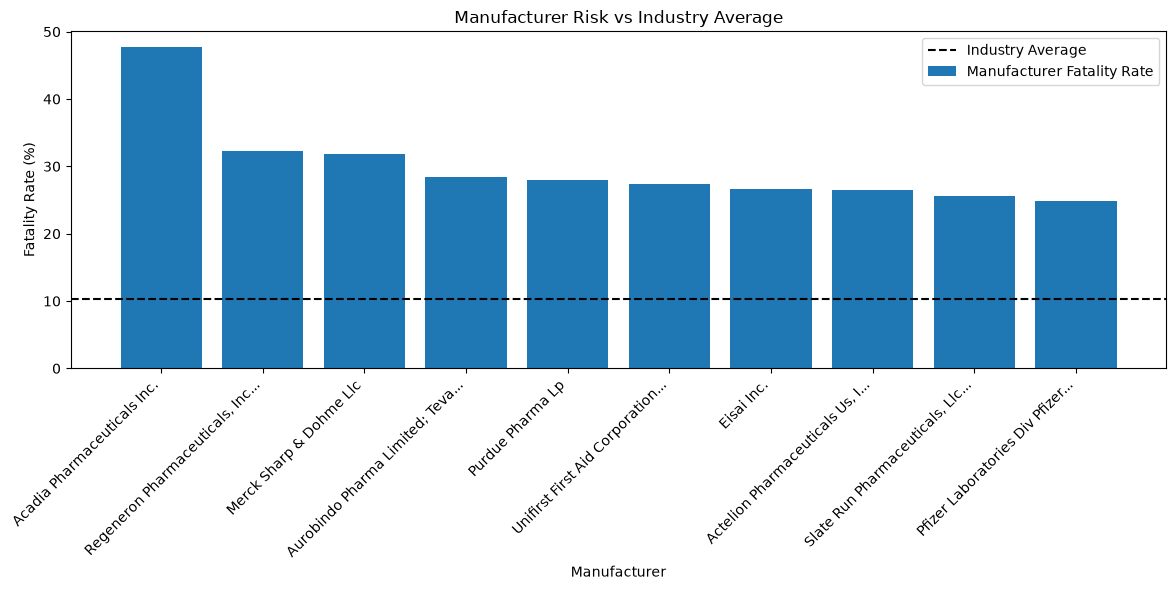

In [32]:
fig, ax = plt.subplots(figsize=(12, 6))
labels = [m[:30] + ('...' if len(m) > 30 else '') for m in q2['manufacturer']]
ax.bar(labels, q2['fatal_rate_pct'], label='Manufacturer Fatality Rate')
ax.axhline(y=q2['industry_average_pct'].iloc[0], linestyle='--', color='black', label='Industry Average')
ax.set_xlabel('Manufacturer')
ax.set_ylabel('Fatality Rate (%)')
ax.set_title('Manufacturer Risk vs Industry Average')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
ax.legend()
plt.tight_layout()
plt.show()

**Insight:** Industry average fatality rate 10.28% hai. Top 10 manufacturers 24.80% se 47.67% tak hain, yaani average se 2.4x se 4.6x zyada. Acadia Pharmaceuticals sabse upar hai (47.67%, 1,605 fatal / 3,367 reports). Ye wahi 1,605 fatal reports hain jo Q1 mein Pimavanserin ke the, to Acadia ka rank poori tarah ek drug se aa raha hai. Regeneron 32.25% (521 reports) aur Merck Sharp & Dohme 31.86% (3,544 reports) agle do hain. Actelion ka rate 26.47% hai par 4,398 reports ke saath volume zyada hai (1,164 fatal).

## Q3. Kya polypharmacy (zyada drugs) aur umr milkar fatality badhate hain?

(Alias `age_bucket` isliye rakha kyunki table mein pehle se `age_group` column hai, aur SQLite `GROUP BY` mein alias ki jagah wahi column utha leta hai.)

In [33]:
Q3 = """
SELECT
    CASE
        WHEN patient_age_years >= 60 THEN 'Older (60+)'
        ELSE 'Below 60'
    END AS age_bucket,

    CASE
        WHEN num_drugs BETWEEN 1 AND 4 THEN '1-4 Drugs'
        WHEN num_drugs BETWEEN 5 AND 9 THEN '5-9 Drugs'
        ELSE '10+ Drugs'
    END AS drug_bucket,

    COUNT(*) AS total_reports,
    SUM(is_fatal) AS fatal_reports,
    ROUND(100.0 * SUM(is_fatal) / COUNT(*), 2) AS fatal_rate_pct

FROM adverse_events
WHERE patient_age_years IS NOT NULL
GROUP BY age_bucket, drug_bucket
ORDER BY age_bucket, drug_bucket;
"""

q3 = sql(Q3)
q3

,age_bucket,drug_bucket,total_reports,fatal_reports,fatal_rate_pct
0,Below 60,1-4 Drugs,93964,6061,6.45
1,Below 60,10+ Drugs,50240,4540,9.04
2,Below 60,5-9 Drugs,44981,3356,7.46
3,Older (60+),1-4 Drugs,88083,13023,14.78
4,Older (60+),10+ Drugs,56418,9480,16.80
5,Older (60+),5-9 Drugs,42805,6474,15.12


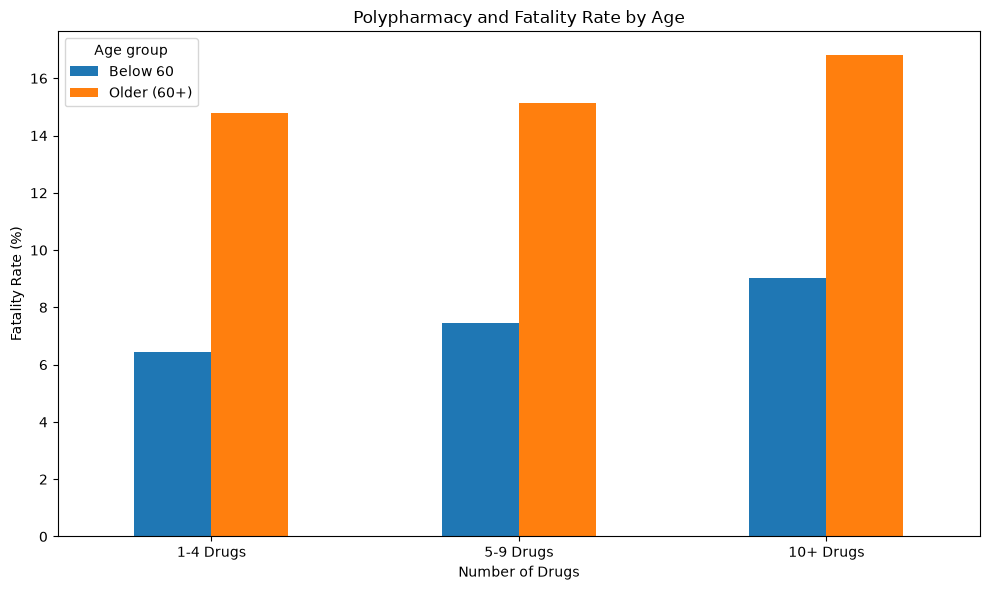

In [34]:
drug_order = ['1-4 Drugs', '5-9 Drugs', '10+ Drugs']
pv = (q3.pivot(index='drug_bucket', columns='age_bucket', values='fatal_rate_pct')
        .reindex(drug_order))

ax = pv[['Below 60', 'Older (60+)']].plot(kind='bar', figsize=(10, 6), rot=0)
ax.set_xlabel('Number of Drugs')
ax.set_ylabel('Fatality Rate (%)')
ax.set_title('Polypharmacy and Fatality Rate by Age')
ax.legend(title='Age group')
plt.tight_layout()
plt.show()

**Insight:** *(Q3 query fix ho gayi hai, isliye is cell ko re-run karke actual numbers yahan bharo: har 6 groups ka fatal rate, aur kya Older (60+) har drug bucket mein Below 60 se upar hai. Purane 24-row output ke numbers galat the, unhe use mat karna.)*

## Q4. Serious aur fatal reports ka share time ke saath behtar ho raha hai ya kharab?

**Note:** Har saal exactly 48,000 reports hain (sampled data), isliye report *count* ka trend mat padho, sirf rates (%) dekho. Data 2015-2025 ka hai.

In [35]:
Q4 = """
SELECT
    year,
    COUNT(*) AS total_reports,

    SUM(CASE WHEN serious = 'Yes' THEN 1 ELSE 0 END)
        AS serious_reports,

    ROUND(
        100.0 * SUM(CASE WHEN serious = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS serious_rate_pct,

    SUM(is_fatal) AS fatal_reports,

    ROUND(
        100.0 * SUM(is_fatal) / COUNT(*), 2
    ) AS fatal_rate_pct

FROM adverse_events
GROUP BY year
ORDER BY year;
"""

q4 = sql(Q4)
q4

,year,total_reports,serious_reports,serious_rate_pct,fatal_reports,fatal_rate_pct
0,2015,48000,37555,78.24,5237,10.91
1,2016,48000,34481,71.84,5006,10.43
2,2017,48000,32832,68.40,4566,9.51
3,2018,48000,34449,71.77,4871,10.15
4,2019,48000,33340,69.46,4450,9.27
5,2020,48000,39054,81.36,8512,17.73
6,2021,48000,36448,75.93,5073,10.57
7,2022,48000,36431,75.90,4496,9.37
8,2023,48000,37250,77.60,4410,9.19
9,2024,48000,33802,70.42,3613,7.53


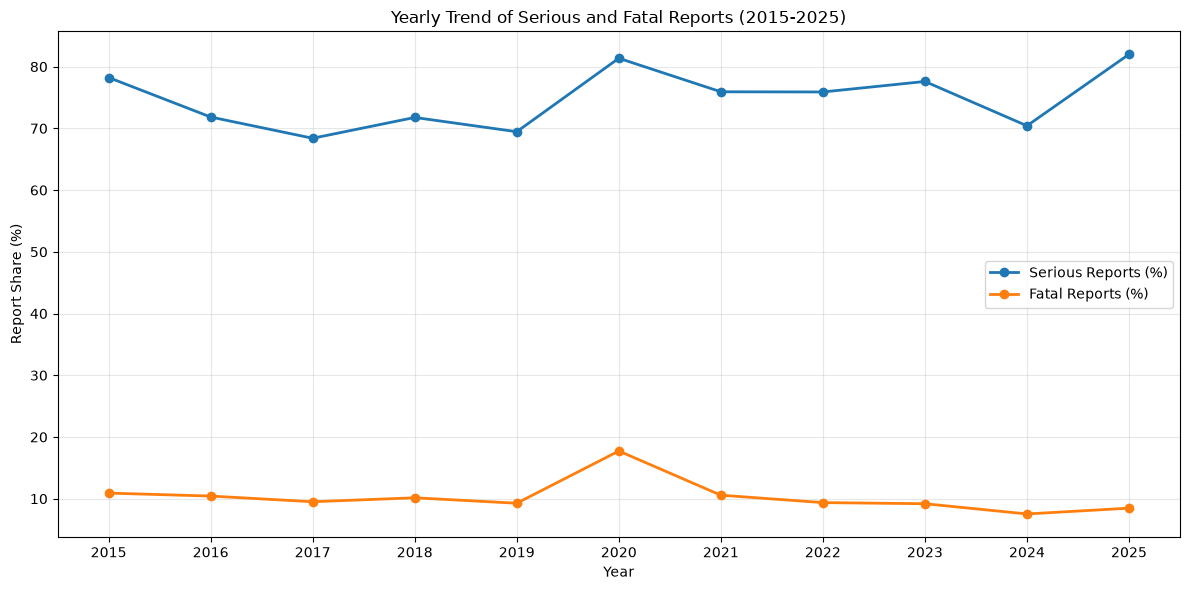

In [36]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(q4['year'], q4['serious_rate_pct'], marker='o', linewidth=2, label='Serious Reports (%)')
ax.plot(q4['year'], q4['fatal_rate_pct'], marker='o', linewidth=2, label='Fatal Reports (%)')
ax.set_xlabel('Year')
ax.set_ylabel('Report Share (%)')
ax.set_title('Yearly Trend of Serious and Fatal Reports (2015-2025)')
ax.set_xticks(q4['year'])
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Insight:** Serious rate ek seedhi line mein nahi chal raha: 78.24% (2015) se gir kar 68.40% (2017), phir 81.36% (2020) tak, aur 82.00% (2025) par sabse zyada. Fatal rate 2015 ke 10.91% se 2024 ke 7.53% tak neeche aaya, 2025 mein 8.47%. Sabse bada outlier 2020 hai: fatal reports 8,512 (17.73%), jabki baaki saalon mein 3,613 se 5,237 ke beech. 2020 ke baad fatal rate 10.57% (2021) se 7.53% (2024) tak girta gaya, to fatal outcomes ka share thoda behtar hua, par serious share abhi bhi 70% se upar hai.

## Q5. Country-wise reports aur fatality (min 100 reports, top 15)

In [37]:
Q5 = """
SELECT
    country,
    COUNT(*) AS total_reports,

    SUM(CASE WHEN serious = 'Yes' THEN 1 ELSE 0 END)
        AS serious_reports,

    ROUND(
        100.0 * SUM(CASE WHEN serious = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS serious_rate_pct,

    SUM(is_fatal) AS fatal_reports,

    ROUND(
        100.0 * SUM(is_fatal) / COUNT(*), 2
    ) AS fatal_rate_pct

FROM adverse_events
WHERE country IS NOT NULL
  AND TRIM(country) != ''
GROUP BY country
HAVING COUNT(*) >= 100
ORDER BY total_reports DESC
LIMIT 15;
"""

q5 = sql(Q5)
q5

,country,total_reports,serious_reports,serious_rate_pct,fatal_reports,fatal_rate_pct
0,US,317456,190122,59.89,25338,7.98
1,CA,54616,53436,97.84,3655,6.69
2,JP,25287,24799,98.07,6011,23.77
3,DE,16414,15907,96.91,2212,13.48
4,FR,15803,15656,99.07,2737,17.32
5,GB,15465,15281,98.81,2576,16.66
6,Unknown,9408,7954,84.55,1038,11.03
7,IT,8408,8278,98.45,987,11.74
8,BR,6645,6502,97.85,563,8.47
9,EU,6113,6056,99.07,897,14.67


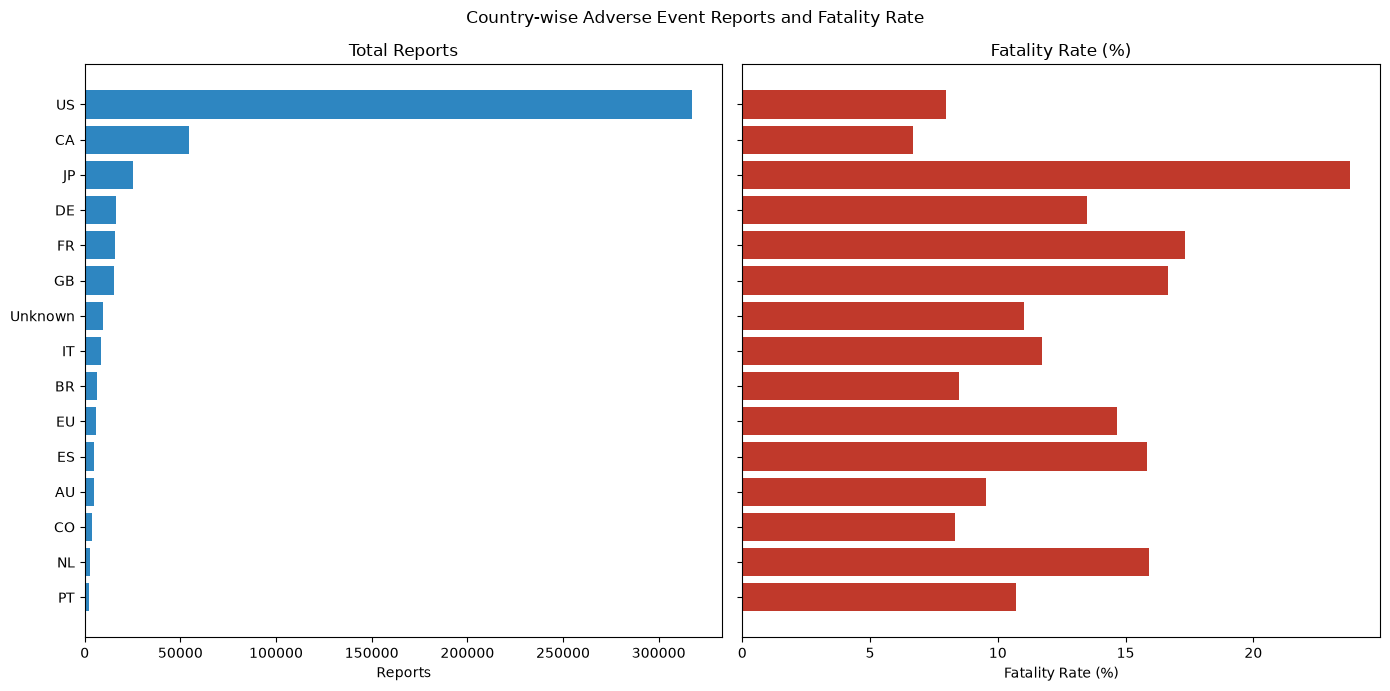

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)

axes[0].barh(q5['country'], q5['total_reports'], color='#2e86c1')
axes[0].set_title('Total Reports')
axes[0].set_xlabel('Reports')
axes[0].invert_yaxis()

axes[1].barh(q5['country'], q5['fatal_rate_pct'], color='#c0392b')
axes[1].set_title('Fatality Rate (%)')
axes[1].set_xlabel('Fatality Rate (%)')

fig.suptitle('Country-wise Adverse Event Reports and Fatality Rate')
plt.tight_layout()
plt.show()

**Insight:** US ke 317,456 reports hain (528,000 mein se 60.1%), fatal rate 7.98%. Japan ka fatal rate sabse zyada hai: 23.77% (6,011 fatal / 25,287 reports), phir France 17.32%, Great Britain 16.66%, Netherlands 15.90%. Canada ke 54,616 reports hain par fatal rate sirf 6.69%. Serious rate mein bada farq hai: US 59.89%, jabki baaki saari top countries 96.51% se 99.07% par hain. Ye likely reporting rules ki wajah se hai (foreign reports mostly serious cases ki hi submit hoti hain), isliye countries ko seedha 'zyada khatarnak' mat bolna.

## Export

## Final Conclusion
- Top drugs/manufacturers ka fatality rate industry average (10.28%) se 2.4x-4.6x zyada hai, par ye reporting-based signal hai, causal risk nahi.
- Fatal rate 2015 (10.91%) se 2025 (8.47%) tak gira hai, 2020 (17.73%) ek spike hai.
- Country comparison mein US ka serious rate (59.89%) baaki countries (96-99%) se bahut alag hai, jo reporting bias ki taraf ishara karta hai.
- Polypharmacy x age ka result Q3 re-run ke baad bharo.

In [39]:
df.to_csv('fda_clean_for_powerbi.csv', index=False)

In [40]:
import os
os.path.abspath('fda_clean_for_powerbi.csv')

'C:\\Users\\HP\\fda_clean_for_powerbi.csv'